# 06. Encoder recurrente con atención

Entrenamos un encoder GRU bidireccional con atención sobre los mismos splits que los notebooks
anteriores. El encoder se entrena con una cabeza MLP (una capa lineal 256 → 1) y después sus
vectores de 256 dimensiones se reutilizan como entrada de un SVM y un XGBoost.

- **Entrada**: tokens del notebook 02, como máximo 1024 (si el prompt es más largo, primeros 512 + últimos 512).
  Todos los OOV comparten el vector `<unk>`; el padding tiene su propio índice con vector de ceros.
- **Paso 1**: cuatro embeddings (word2vec original congelado y ajustable, word2vec propio congelado y ELMo congelado).
- **Paso 2**: ablaciones sobre el mejor embedding (sin atención, truncado solo principio, longitud 512).
- **Paso 3**: SVM y XGBoost sobre los vectores del mejor encoder, comparados con la cabeza MLP.

Los vectores de ELMo se leen de la caché que genera el **notebook 05**, que hay que ejecutar antes.
Este notebook no importa TensorFlow.

Todas las decisiones se toman con validación completa. Como en el notebook 04, también se informa
de validación sin los prompts con marcadores (`[PROMPT]` / `[TARGETLANGUAGE]`), pero solo se
reporta. Test se usa una sola vez, al final, para el modelo final.
El modelo, los datos y el bucle de entrenamiento están en `src/jailbreak_detection/models/`.

## Comprobación del entorno

El `torch` del lock puede no ser compatible con el driver del servidor; en ese caso CUDA no está
disponible y todo se entrenaría en CPU. Esta celda lo comprueba antes de lanzar nada.

In [1]:
import torch
from IPython.display import HTML, display

print("torch", torch.__version__, "| compilado para CUDA", torch.version.cuda)
print("CUDA disponible:", torch.cuda.is_available())
cuda_ok = False
if torch.cuda.is_available():
    try:
        torch.ones(1, device="cuda").add_(1).item()   # falla si el driver no admite esta build
        cuda_ok = True
        print("GPU:", torch.cuda.get_device_name(0))
    except Exception as e:
        print("CUDA aparece como disponible pero no funciona:", e)
if not cuda_ok:
    display(HTML(
        '<div style="background:#c0392b;color:white;padding:14px;font-size:18px;font-weight:bold">'
        '⚠ SIN GPU: los entrenamientos se van a ejecutar en CPU.<br>'
        '<span style="font-size:14px;font-weight:normal">Si esto es el servidor, revisa el driver '
        'y la build de torch (torch.version.cuda) antes de lanzar los 7 entrenamientos.</span></div>'))

torch 2.15.0+cu132 | compilado para CUDA 13.2
CUDA disponible: True


GPU: Tesla T4


## Configuración

Con `QUICK = True` se usa un subconjunto pequeño de cada split, una sola época y pocas pruebas
de Optuna: sirve para comprobar que todo el flujo funciona antes de lanzar los entrenamientos
completos. Sus resultados se guardan en carpetas distintas (`*_quick`) para no mezclarse con los
reales, y necesita la caché de ELMo del notebook 05 ejecutado también con `QUICK = True`.

Cada experimento guarda al terminar su checkpoint y sus métricas en `outputs/` (ignorado por git).
Si el notebook se vuelve a ejecutar, los experimentos que ya tienen `metrics.json` no se repiten.

In [2]:
import json
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from jailbreak_detection.models.analysis import attention_html, metrics_by_length
from jailbreak_detection.models.data import UNK_IDX, load_splits, select_splits, validation_masks
from jailbreak_detection.models.embeddings import EMBEDDINGS, EmbeddingStore
from jailbreak_detection.models.heads import build_head, head_scores, score_grid, tune_head
from jailbreak_detection.models.training import (PROB_GRID, ExperimentConfig, attention_weights,
                                                 best_by_val_mcc, evaluate, load_model,
                                                 load_result, predict, run_experiment, set_seed,
                                                 tune_threshold)

# Modo rápido: subconjunto pequeño + 1 época, para verificar el flujo antes de lo completo
QUICK = False

SEED = 42
set_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"

DATA = Path("../data")
TAG = "_quick" if QUICK else ""
OUT = Path(f"../outputs/deep_encoder{TAG}")    # checkpoints, métricas, vectores y predicciones
TB = Path(f"../runs/deep_encoder{TAG}")        # logs de TensorBoard
ELMO_CACHE = Path(f"../outputs/elmo_cache{TAG}")  # vectores de ELMo (notebook 05)
CACHE = Path("../outputs/cache")               # matrices de word2vec (no dependen del modo)
OUT.mkdir(parents=True, exist_ok=True)
N_TRIALS = 3 if QUICK else 25   # pruebas de Optuna por cabeza (25, como en el notebook 04)
METRICS = ["F1", "Accuracy", "Precision", "Recall", "MCC"]   # mismas columnas que el notebook 04

print("Dispositivo de entrenamiento:", device)

Dispositivo de entrenamiento: cuda


## Datos

Usamos los JSONL tokenizados del notebook 02 sin rehacer los splits. El vocabulario es el del
word2vec propio del notebook 03, que se construyó solo con train (`min_count=1`): `EmbeddingStore`
comprueba que coincide exactamente con los tokens de train antes de usarlo.

`pos_weight` = nº de normales / nº de jailbreaks en train completo (también en modo rápido).
La máscara «sin marcadores» usa la misma detección que el notebook 04 y solo se aplica al evaluar.

In [3]:
splits = load_splits(DATA / "interim")
pos_weight = float((splits["train"]["label"] == 0).sum() / (splits["train"]["label"] == 1).sum())

store = EmbeddingStore(
    DATA / "processed/word2vec_trained_from_zero.model",
    CACHE,
    ELMO_CACHE,
    splits["train"]["tokens_flat"],
)

data = select_splits(splits, QUICK)
train_df, val_df, test_df = data["train"], data["val"], data["test"]
y = {s: df["label"].to_numpy() for s, df in data.items()}
val_masks = validation_masks(val_df)

print(f"pos_weight = {pos_weight:.4f} | vocabulario de train: {len(store.vocab):,} tokens")
print(f"Validación sin marcadores: {val_masks['Sin marcadores'].sum()} de {len(val_df)} prompts")
pd.DataFrame([{
    "Split": name,
    "Prompts": len(df),
    "Jailbreaks": int(df["label"].sum()),
    "% jailbreak": 100 * df["label"].mean(),
    "Mediana tokens": df["n_tokens"].median(),
    "> 512 tokens": int((df["n_tokens"] > 512).sum()),
    "> 1024 tokens": int((df["n_tokens"] > 1024).sum()),
} for name, df in data.items()]).round(2)

pos_weight = 10.2596 | vocabulario de train: 82,469 tokens
Validación sin marcadores: 1518 de 2015 prompts


,Split,Prompts,Jailbreaks,% jailbreak,Mediana tokens,> 512 tokens,> 1024 tokens
0,train,9672,859,8.88,170.0,1917,659
1,val,2015,165,8.19,171.0,417,131
2,test,2019,183,9.06,183.0,368,134


### Matrices de embeddings y OOV

- **word2vec original**: una fila por token de train que existe en Google News; el resto de tokens
  (también los de train que no están en Google News) van a `<unk>`.
- **word2vec propio**: Google News más los vectores entrenados en el notebook 03 para los tokens de
  train que faltaban; solo son OOV los tokens que no aparecen en train.
- `<unk>` es un vector aleatorio fijo (semilla 42, misma desviación típica que los vectores);
  `<pad>` es el índice 0 con vector de ceros.

La primera vez se carga Google News (`gensim.downloader`, como en el notebook 03) y las matrices
reducidas se guardan en `outputs/cache/`.

In [4]:
oov_rows = []
for name in ["w2v_google_frozen", "w2v_domain_frozen"]:
    pipe = store.get(name)
    oov_rows.append({
        "Embedding": name.replace("_frozen", ""),
        "Filas (con pad y unk)": pipe.matrix.shape[0],
        **{f"% OOV {s}": 100 * pipe.index.oov_rate(splits[s]["tokens_flat"]) for s in splits},
    })
pd.DataFrame(oov_rows).round(2)

,Embedding,Filas (con pad y unk),% OOV train,% OOV val,% OOV test
0,w2v_google,50482,29.48,29.96,30.26
1,w2v_domain,82471,0.00,2.34,2.13


## TensorBoard

Cada entrenamiento se registra en `runs/deep_encoder/<embedding>__<atención>__<truncado>__L<longitud>`.
Por época: pérdida de train y validación y MCC, precisión, recall y F1 de validación (umbral 0.5).
Al terminar, la pestaña *HPARAMS* recoge la configuración, las métricas de validación con el umbral
ajustado, la mejor época y el umbral elegido.

Desde la raíz del repositorio:

```bash
uv run tensorboard --logdir runs/deep_encoder
```

En el servidor, añadir `--bind_all` o abrir un túnel (`ssh -L 6006:localhost:6006 <servidor>`) y
entrar en http://localhost:6006.

## Entrenamiento

Mismos hiperparámetros en todos los experimentos (`ExperimentConfig`): BCEWithLogitsLoss con
`pos_weight`, AdamW (lr 1e-3, weight decay 0.01), clipping a norma 1.0, dropout 0.3 en los
embeddings y en el vector de 256, batch de 32 agrupado por longitud y hasta 30 épocas con early
stopping sobre el MCC de validación completa (umbral 0.5, paciencia 5), restaurando la mejor época.
Después se ajusta el umbral en validación completa para maximizar MCC; ese umbral es el que se usa
después, también para la columna «Sin marcadores».

In [5]:
results = {}


def train(cfg):
    result = load_result(OUT / cfg.name)
    if result is None:
        if QUICK:
            cfg = replace(cfg, max_epochs=1)
        pipe = store.get(cfg.embedding, cfg.truncation, cfg.max_len)
        result = run_experiment(cfg, pipe, train_df, val_df, pos_weight, OUT, TB, device)
    else:
        print(f"[{cfg.name}] ya entrenado: se cargan sus métricas.")
    results[cfg.name] = result
    return result


def val_table(names):
    # Formato del notebook 04: una fila por modelo y subconjunto de validación
    rows = []
    for name in names:
        r = results[name]
        probs = np.load(OUT / name / "val_probs.npy")
        for variant, mask in val_masks.items():
            rows.append({"Configuración": name, "Validation": variant,
                         **evaluate(y["val"][mask], probs[mask] >= r["threshold"]),
                         "MCC@0.5": evaluate(y["val"][mask], probs[mask] >= 0.5)["MCC"],
                         "Umbral": r["threshold"], "Mejor época": r["best_epoch"],
                         "Minutos": r["train_seconds"] / 60})
    table = pd.DataFrame(rows)
    # Ordenado por MCC en validación completa, con sus dos filas juntas
    order = sorted(names, key=lambda n: -results[n]["val_tuned"]["MCC"])
    table["_o"] = table["Configuración"].map(order.index)
    return table.sort_values(["_o", "Validation"], ascending=[True, False]).drop(columns="_o").reset_index(drop=True)

## Paso 1: elección del embedding

Las cuatro variantes con atención, 1024 tokens y truncado principio + final. En ELMo, los vectores
precalculados en el notebook 05 (media de las tres capas, 1024 dimensiones, sobre la secuencia ya
truncada) entran en la GRU; si falta la caché, el entrenamiento falla indicando qué ejecutar.

In [6]:
step1 = [ExperimentConfig(embedding=name) for name in EMBEDDINGS]
for cfg in step1:
    train(cfg)

[w2v_google_frozen__attn__head_tail__L1024] ya entrenado: se cargan sus métricas.
[w2v_google_finetuned__attn__head_tail__L1024] ya entrenado: se cargan sus métricas.
[w2v_domain_frozen__attn__head_tail__L1024] ya entrenado: se cargan sus métricas.
[elmo_frozen__attn__head_tail__L1024] ya entrenado: se cargan sus métricas.


In [7]:
best_step1 = best_by_val_mcc({cfg.name: results[cfg.name] for cfg in step1})
best_embedding = results[best_step1]["config"]["embedding"]
print("Embedding ganador (MCC en validación completa, umbral ajustado):", best_embedding)
val_table([cfg.name for cfg in step1]).round(4)

Embedding ganador (MCC en validación completa, umbral ajustado): elmo_frozen


,Configuración,Validation,F1,Accuracy,Precision,Recall,MCC,MCC@0.5,Umbral,Mejor época,Minutos
0,elmo_frozen__attn__head_tail__L1024,Todos,0.6211,0.9340,0.5860,0.6606,0.5863,0.5695,0.57,9,13.0978
1,elmo_frozen__attn__head_tail__L1024,Sin marcadores,0.6372,0.9190,0.6171,0.6585,0.5920,0.5730,0.57,9,13.0978
2,w2v_domain_frozen__attn__head_tail__L1024,Todos,0.6022,0.9285,0.5533,0.6606,0.5660,0.5660,0.50,13,2.8372
3,w2v_domain_frozen__attn__head_tail__L1024,Sin marcadores,0.6067,0.9078,0.5625,0.6585,0.5571,0.5571,0.50,13,2.8372
4,w2v_google_finetuned__attn__head_tail__L1024,Todos,0.5868,0.9350,0.6118,0.5636,0.5521,0.5162,0.70,2,1.4209
5,w2v_google_finetuned__attn__head_tail__L1024,Sin marcadores,0.5974,0.9183,0.6389,0.5610,0.5536,0.5188,0.70,2,1.4209
6,w2v_google_frozen__attn__head_tail__L1024,Todos,0.5681,0.9261,0.5444,0.5939,0.5284,0.4964,0.61,7,2.0110
7,w2v_google_frozen__attn__head_tail__L1024,Sin marcadores,0.5791,0.9071,0.5673,0.5915,0.5271,0.4901,0.61,7,2.0110


## Paso 2: ablaciones

Sobre la configuración ganadora del paso 1 cambiamos una sola cosa cada vez:
(a) sin atención (estado final de cada dirección), (b) truncado solo principio (primeros 1024 tokens)
y (c) longitud máxima 512 (256 + 256). Si el ganador es ELMo, (b) y (c) necesitan sus propias
cachés: el notebook 05 las genera al volver a ejecutarlo, porque lee el ganador de estos resultados.

In [8]:
base = ExperimentConfig(embedding=best_embedding)
step2 = [
    replace(base, use_attention=False),
    replace(base, truncation="head"),
    replace(base, max_len=512),
]
for cfg in step2:
    train(cfg)

[elmo_frozen__noattn__head_tail__L1024] ya entrenado: se cargan sus métricas.


[elmo_frozen__attn__head__L1024] train=9672 val=2015 | parámetros entrenables: 919,553 | dispositivo: cuda


/content/repo/.venv/lib/python3.13/site-packages/triton/knobs.py:504: UserWarning: TRITON_DEFAULT_FP_FUSION is unset: defaulting to FP fusion ENABLED for backward compatibility in Triton 3.9. The default will change to DISABLED in Triton 3.10; set TRITON_DEFAULT_FP_FUSION=1 to keep fusion enabled or =0 to adopt the new default early and silence this warning.
  warn_once(FP_FUSION_DEFAULT_WARNING)


[elmo_frozen__attn__head__L1024] época 01 | loss train 0.8334 val 0.7512 | MCC 0.3866 P 0.254 R 0.855 F1 0.391 | 69s *


[elmo_frozen__attn__head__L1024] época 02 | loss train 0.7250 val 1.0142 | MCC 0.4957 P 0.492 R 0.594 F1 0.538 | 58s *


[elmo_frozen__attn__head__L1024] época 03 | loss train 0.6117 val 0.9210 | MCC 0.4823 P 0.415 R 0.691 F1 0.518 | 51s


... (34 outputs left out)

[elmo_frozen__attn__head_tail__L512] época 13 | loss train 0.1452 val 3.2719 | MCC 0.4884 P 0.634 R 0.430 F1 0.513 | 35s


[elmo_frozen__attn__head_tail__L512] época 14 | loss train 0.1011 val 2.2900 | MCC 0.5265 P 0.532 R 0.606 F1 0.567 | 39s


[elmo_frozen__attn__head_tail__L512] época 15 | loss train 0.0966 val 2.7625 | MCC 0.5214 P 0.597 R 0.521 F1 0.557 | 39s
[elmo_frozen__attn__head_tail__L512] early stopping: 5 épocas sin mejorar.


[elmo_frozen__attn__head_tail__L512] mejor época 10 | umbral 0.76 | MCC val 0.5566 (a 0.5: 0.5379)


In [9]:
all_names = [cfg.name for cfg in step1 + step2]
best_name = best_by_val_mcc({name: results[name] for name in all_names})
best_cfg = ExperimentConfig(**results[best_name]["config"])
print("Mejor configuración (MCC en validación completa):", best_name)
table_configs = val_table(all_names)
table_configs.round(4)

Mejor configuración (MCC en validación completa): elmo_frozen__attn__head_tail__L1024


,Configuración,Validation,F1,Accuracy,Precision,Recall,MCC,MCC@0.5,Umbral,Mejor época,Minutos
0,elmo_frozen__attn__head_tail__L1024,Todos,0.6211,0.9340,0.5860,0.6606,0.5863,0.5695,0.57,9,13.0978
1,elmo_frozen__attn__head_tail__L1024,Sin marcadores,0.6372,0.9190,0.6171,0.6585,0.5920,0.5730,0.57,9,13.0978
2,elmo_frozen__noattn__head_tail__L1024,Todos,0.6125,0.9385,0.6323,0.5939,0.5794,0.5715,0.66,11,16.6158
3,elmo_frozen__noattn__head_tail__L1024,Sin marcadores,0.6178,0.9209,0.6467,0.5915,0.5746,0.5671,0.66,11,16.6158
4,w2v_domain_frozen__attn__head_tail__L1024,Todos,0.6022,0.9285,0.5533,0.6606,0.5660,0.5660,0.50,13,2.8372
5,w2v_domain_frozen__attn__head_tail__L1024,Sin marcadores,0.6067,0.9078,0.5625,0.6585,0.5571,0.5571,0.50,13,2.8372
6,elmo_frozen__attn__head_tail__L512,Todos,0.5755,0.9414,0.7080,0.4848,0.5566,0.5379,0.76,10,9.9706
7,elmo_frozen__attn__head_tail__L512,Sin marcadores,0.5830,0.9256,0.7383,0.4817,0.5591,0.5365,0.76,10,9.9706
8,elmo_frozen__attn__head__L1024,Todos,0.5775,0.9404,0.6891,0.4970,0.5548,0.5548,0.50,18,23.3625
9,elmo_frozen__attn__head__L1024,Sin marcadores,0.5806,0.9229,0.7043,0.4939,0.5500,0.5500,0.50,18,23.3625


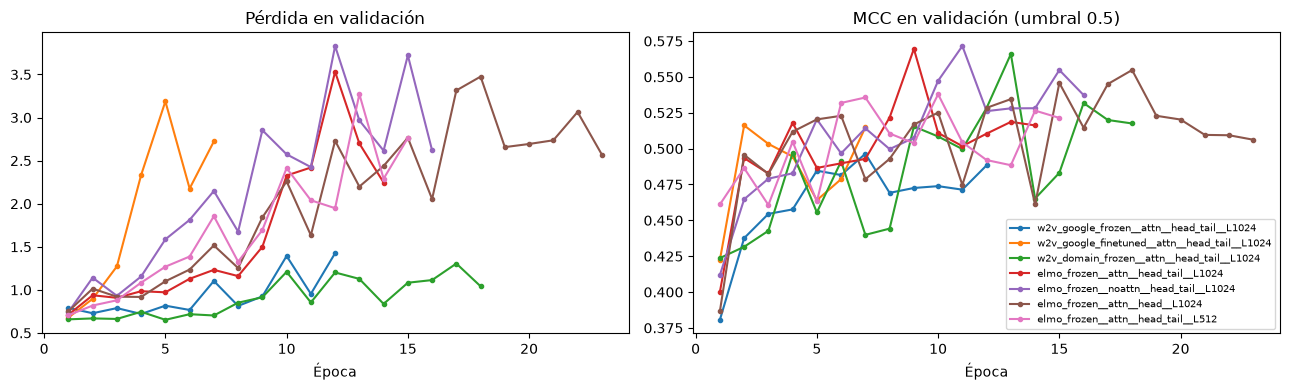

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for name in all_names:
    h = pd.DataFrame(results[name]["history"])
    axes[0].plot(h["epoch"], h["val_loss"], marker=".", label=name)
    axes[1].plot(h["epoch"], h["MCC"], marker=".", label=name)
axes[0].set(title="Pérdida en validación", xlabel="Época")
axes[1].set(title="MCC en validación (umbral 0.5)", xlabel="Época")
axes[1].legend(fontsize=7, loc="lower right")
plt.tight_layout()
plt.show()

## Paso 3: cabezas sobre los vectores del encoder

Con la mejor de las 7 configuraciones y el encoder congelado (modo eval, sin dropout) extraemos el
vector de 256 dimensiones de train y validación. SVM y XGBoost se ajustan como en el notebook 04:
se entrenan con todo train y Optuna (TPE, semilla 42, 25 pruebas) elige los hiperparámetros por MCC
en validación completa; el desbalance se trata con `class_weight` en LinearSVC y `scale_pos_weight`
en XGBoost (Optuna elige entre sin peso y nº normales / nº jailbreaks). Después se ajusta el umbral
en validación completa como con el MLP: sobre la probabilidad en XGBoost y sobre `decision_function`
en el SVM (percentiles 1–99 de las puntuaciones de validación y el 0).

In [11]:
best_dir = OUT / best_name
best_pipe = store.get(best_cfg.embedding, best_cfg.truncation, best_cfg.max_len)
best_model = load_model(best_dir, best_pipe, device)
datasets = {s: best_pipe.dataset(df, best_cfg.max_len, best_cfg.truncation) for s, df in data.items()}


def vectors(split):
    path = best_dir / f"vectors_{split}.npy"
    if not path.exists():
        np.save(path, predict(best_model, best_pipe, datasets[split], device, what="vectors"))
    return np.load(path)


X = {s: vectors(s) for s in ["train", "val"]}
print({s: x.shape for s, x in X.items()})

{'train': (9672, 256), 'val': (2015, 256)}


In [12]:
heads = {}
for head_name, prefix in [("LinearSVC", "svc"), ("XGBoost", "xgb")]:
    params_path = best_dir / f"{prefix}_best_params.json"
    if params_path.exists():
        params = json.loads(params_path.read_text())
        clf = build_head(head_name, params).fit(X["train"], y["train"])
    else:
        params, clf, study = tune_head(head_name, X["train"], y["train"], X["val"], y["val"],
                                       n_trials=N_TRIALS)
        params_path.write_text(json.dumps(params, indent=2))
    scores = head_scores(clf, X["val"])
    grid = score_grid(scores) if head_name == "LinearSVC" else PROB_GRID
    default = 0.0 if head_name == "LinearSVC" else 0.5
    threshold, _ = tune_threshold(y["val"], scores, grid=grid, default=default)
    heads[head_name] = {"model": clf, "params": params, "threshold": threshold, "default": default}
    print(head_name, params, "| umbral:", round(threshold, 4))

# Puntuaciones de validación y umbral de cada cabeza (la MLP es la del propio encoder)
head_val = {"MLP": (np.load(best_dir / "val_probs.npy"), results[best_name]["threshold"], 0.5)}
for head_name, h in heads.items():
    head_val[head_name] = (head_scores(h["model"], X["val"]), h["threshold"], h["default"])

rows = []
for head_name, (scores, threshold, default) in head_val.items():
    for variant, mask in val_masks.items():
        rows.append({"Cabeza": head_name, "Validation": variant,
                     **evaluate(y["val"][mask], scores[mask] >= threshold),
                     "MCC umbral defecto": evaluate(y["val"][mask], scores[mask] >= default)["MCC"],
                     "Umbral": threshold})
table_heads = pd.DataFrame(rows)
print("Encoder:", best_name)
table_heads.round(4)

LinearSVC {'C': 0.017988265774904966, 'penalty': 'l1', 'class_weight': None} | umbral: 0.163


XGBoost {'n_estimators': 200, 'max_depth': 8, 'learning_rate': 0.22588599208344728, 'min_child_weight': 6, 'subsample': 0.6314646401956925, 'colsample_bytree': 0.9830423995627585, 'scale_pos_weight': 10.259604190919674} | umbral: 0.58
Encoder: elmo_frozen__attn__head_tail__L1024


,Cabeza,Validation,F1,Accuracy,Precision,Recall,MCC,MCC umbral defecto,Umbral
0,MLP,Todos,0.6211,0.9340,0.5860,0.6606,0.5863,0.5695,0.570
1,MLP,Sin marcadores,0.6372,0.9190,0.6171,0.6585,0.5920,0.5730,0.570
2,LinearSVC,Todos,0.6078,0.9404,0.6596,0.5636,0.5779,0.5707,0.163
3,LinearSVC,Sin marcadores,0.6195,0.9256,0.6917,0.5610,0.5827,0.5743,0.163
4,XGBoost,Todos,0.6361,0.9409,0.6420,0.6303,0.6040,0.5974,0.580
5,XGBoost,Sin marcadores,0.6458,0.9256,0.6645,0.6280,0.6045,0.5969,0.580


## Evaluación final en test

Todo lo anterior (embedding, configuración, umbrales e hiperparámetros) se ha decidido con
validación completa. El modelo final es el encoder de la mejor configuración con la cabeza de mayor
MCC en validación completa. Se evalúa aquí en todo test, una sola vez, sin reentrenar ni ajustar nada.

In [13]:
val_full = table_heads[table_heads["Validation"] == "Todos"].set_index("Cabeza")
final_head = val_full["MCC"].idxmax()
if final_head == "MLP":
    test_scores = predict(best_model, best_pipe, datasets["test"], device)[0]
else:
    test_scores = head_scores(heads[final_head]["model"], vectors("test"))
test_pred = test_scores >= head_val[final_head][1]

final_test = pd.DataFrame([{"Configuración": best_name, "Cabeza": final_head,
                            "Umbral": head_val[final_head][1], **evaluate(y["test"], test_pred)}])
final_test.round(4)

,Configuración,Cabeza,Umbral,F1,Accuracy,Precision,Recall,MCC
0,elmo_frozen__attn__head_tail__L1024,XGBoost,0.58,0.6136,0.9326,0.6391,0.5902,0.5774


## Análisis del modelo final

### Resultados por longitud del prompt

Tramos según la longitud original en tokens (antes de truncar), con las predicciones de test del
modelo final de la celda anterior. *Recall* es la fracción de jailbreaks detectados en el tramo y
*FPR normales* la fracción de prompts normales marcados como jailbreak: permiten ver cómo se
comporta con jailbreaks cortos y con prompts normales largos. Con pocos ejemplos o una sola clase
en el tramo, MCC no está definido (NaN).

In [14]:
print(f"Modelo final: {best_name} + {final_head}")
metrics_by_length(test_df["n_tokens"], y["test"], test_pred).round(3)

Modelo final: elmo_frozen__attn__head_tail__L1024 + XGBoost


,Tramo,n,Jailbreaks,MCC,Precision,Recall,F1,FPR normales
0,1-64,455,16,0.242,0.286,0.250,0.267,0.023
1,65-256,761,54,0.588,0.640,0.593,0.615,0.025
2,257-512,435,54,0.608,0.680,0.630,0.654,0.042
3,513-1024,234,40,0.687,0.732,0.750,0.741,0.057
4,>1024,134,19,0.421,0.571,0.421,0.485,0.052


### Pesos de atención

Si el modelo final tiene atención, mostramos prompts de test acertados y fallados según sus
predicciones (las de la evaluación final); los pesos son los del encoder. Si no tiene atención,
usamos la ganadora del paso 1 (misma entrada, con atención) sobre prompts de **validación**, para no
evaluar en test otro modelo distinto del final.

El color es el peso de cada token relativo al máximo del prompt (al pasar el ratón se ve el peso),
los tokens subrayados son los que el modelo vio como `<unk>` y `[… truncado …]` marca el corte del
truncado principio + final.

In [15]:
if best_cfg.use_attention:
    attn_name, attn_split, attn_pred = best_name, "test", test_pred
    attn_model, attn_pipe, attn_ds = best_model, best_pipe, datasets["test"]
else:
    attn_name, attn_split = best_step1, "val"
    attn_cfg = ExperimentConfig(**results[attn_name]["config"])
    attn_pipe = store.get(attn_cfg.embedding, attn_cfg.truncation, attn_cfg.max_len)
    attn_model = load_model(OUT / attn_name, attn_pipe, device)
    attn_ds = attn_pipe.dataset(val_df, attn_cfg.max_len, attn_cfg.truncation)
    attn_pred = np.load(OUT / attn_name / "val_probs.npy") >= results[attn_name]["threshold"]
attn_cfg = ExperimentConfig(**results[attn_name]["config"])
attn_df, attn_y = data[attn_split], y[attn_split]

rng = np.random.default_rng(SEED)
short = attn_ds.lengths <= 300   # preferimos prompts legibles
cases = {"Jailbreak detectado (TP)": (attn_y == 1) & attn_pred,
         "Jailbreak no detectado (FN)": (attn_y == 1) & ~attn_pred,
         "Normal marcado como jailbreak (FP)": (attn_y == 0) & attn_pred,
         "Normal acertado (TN)": (attn_y == 0) & ~attn_pred}
print(f"Pesos de: {attn_name} | ejemplos de {attn_split}")
for case, mask in cases.items():
    pool = np.flatnonzero(mask & short) if (mask & short).sum() >= 2 else np.flatnonzero(mask)
    chosen = rng.choice(pool, size=min(2, len(pool)), replace=False) if len(pool) else []
    for (weights, prob), i in zip(attention_weights(attn_model, attn_pipe, attn_ds, chosen, device), chosen):
        tokens = attn_ds.tokens[i]
        unk = None if attn_pipe.index is None else np.array(attn_ds.items[i]) == UNK_IDX
        n_orig = int(attn_df["n_tokens"].iloc[i])
        cut = attn_cfg.max_len // 2 if attn_cfg.truncation == "head_tail" and n_orig > attn_cfg.max_len else None
        title = f"{case} | P(jailbreak) del MLP = {prob:.3f} | {n_orig} tokens"
        display(HTML(attention_html(tokens, weights, unk_mask=unk, title=title, gap_after=cut)))

Pesos de: elmo_frozen__attn__head_tail__L1024 | ejemplos de test


## Conclusiones

*(Completar tras la ejecución completa en el servidor: embedding ganador y por qué, efecto de cada
ablación, comparación de las tres cabezas y con los modelos shallow del notebook 04 (mismas
columnas y mismos subconjuntos de validación), y qué muestran el análisis por longitud y los pesos
de atención.)*